# RenalGuard — Stage 6: Advanced Model Evaluation and Explainable AI (XAI)
## Clinical Diagnostic Metrics, Error Breakdown, Permutation Importance, and SHAP Interpretability

Welcome to Stage 6 of **RenalGuard**!

### Why Advanced Evaluation & Explainability are Critical in Healthcare AI
1. **The "Black Box" Problem**: In clinical medicine, a physician cannot ethically prescribe treatment based purely on a machine's output without understanding *why* the prediction was made.
2. **Asymmetric Clinical Costs**: Missing a true CKD patient (False Negative) can result in untreated progression toward End-Stage Renal Disease (ESRD) and emergency dialysis, whereas an unnecessary follow-up test (False Positive) is minor.
3. **Rigorous Auditability**: We evaluate the serialized candidate model (`Random Forest Pipeline`) strictly on the held-out test cohort ($N=80$) without retraining or modifying test splits.


---
## Step 1: Load Candidate Pipeline and Held-Out Test Data

We load the candidate pipeline saved in Stage 5 from `models/candidate_model_pipeline.joblib`.
- Target labels:
  - `1` = **Chronic Kidney Disease (CKD)** (Positive Class)
  - `0` = **Healthy / Non-CKD** (Negative Class)
- Test set size: **80 patients** (50 CKD, 30 Healthy).


In [3]:
import os
import sys
import pandas as pd
import numpy as np
import joblib

# Ensure root directory is accessible
sys.path.insert(0, os.path.abspath('..'))

from src.preprocessing import load_and_clean_data, split_data

# 1. Load fitted candidate pipeline
model_path = os.path.join('..', 'models', 'candidate_model_pipeline.joblib')
pipeline = joblib.load(model_path)
print(f"Candidate Pipeline loaded: {type(pipeline)}")
print(f"Pipeline stages: {[step[0] for step in pipeline.steps]}")

# 2. Load and split dataset (exact same 80:20 stratified split, random_state=42)
data_path = os.path.join('..', 'data', 'chronic_kidney_disease.csv')
df = load_and_clean_data(data_path)
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)

print(f"\nHeld-out test set loaded:")
print(f" - Patients: {len(X_test)}")
print(f" - True Positives available (CKD=1): {(y_test == 1).sum()}")
print(f" - True Negatives available (Healthy=0): {(y_test == 0).sum()}")


Candidate Pipeline loaded: <class 'sklearn.pipeline.Pipeline'>
Pipeline stages: ['preprocessor', 'classifier']

Held-out test set loaded:
 - Patients: 80
 - True Positives available (CKD=1): 50
 - True Negatives available (Healthy=0): 30


---
## Step 2: Diagnostic Confusion Matrix & Clinical Error Analysis

**Clinical Concepts**:
- **True Positive (TP)**: Patient has CKD and the model correctly diagnoses CKD ($49$ patients).
- **True Negative (TN)**: Patient is healthy and the model correctly confirms healthy status ($30$ patients).
- **False Positive (FP)**: Model falsely flags a healthy patient as having CKD ($0$ patients).
- **False Negative (FN)**: Model misses a patient who actually has CKD, telling them they are healthy ($1$ patient).

### Implications of False Negatives in Healthcare Screening
A **False Negative** is the most hazardous outcome in clinical screening:
1. **Silent Disease Progression**: CKD often progresses asymptomatically. By the time symptoms appear, renal nephrons are permanently scarred.
2. **Lost Therapeutic Window**: Early interventions (lifestyle modifications, tight blood pressure control, ACE inhibitors/ARBs, and SGLT2 inhibitors) can halt or dramatically slow progression if caught early. Missing the diagnosis eliminates this window.
3. **Escalation to Dialysis**: Unmonitored CKD frequently ends in emergency department admissions with acute uremia, requiring emergent hemodialysis catheter placement.


Confusion Matrix Breakdown (Total N=80):
 - True Negatives  (TN): 30
 - False Positives (FP): 0
 - False Negatives (FN): 1
 - True Positives  (TP): 49


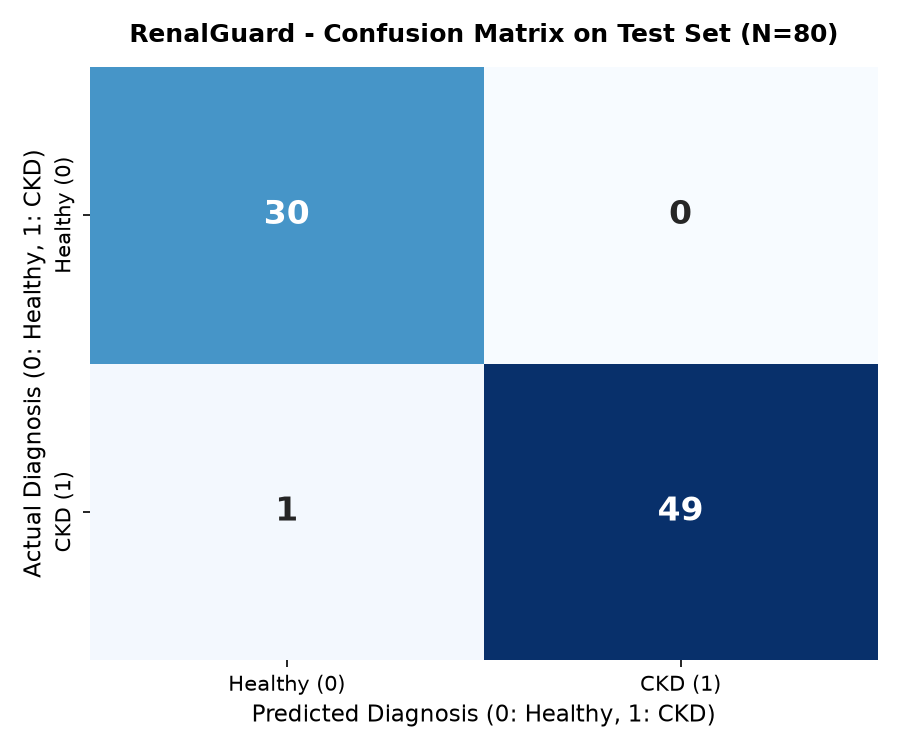

In [5]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion Matrix Breakdown (Total N=80):")
print(f" - True Negatives  (TN): {tn}")
print(f" - False Positives (FP): {fp}")
print(f" - False Negatives (FN): {fn}")
print(f" - True Positives  (TP): {tp}")

# Plotting Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    annot_kws={'size': 16, 'fontweight': 'bold'}
)
plt.title('RenalGuard - Confusion Matrix on Test Set (N=80)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Predicted Diagnosis (0: Healthy, 1: CKD)', fontsize=11)
plt.ylabel('Actual Diagnosis (0: Healthy, 1: CKD)', fontsize=11)
plt.xticks([0.5, 1.5], ['Healthy (0)', 'CKD (1)'], fontsize=10)
plt.yticks([0.5, 1.5], ['Healthy (0)', 'CKD (1)'], fontsize=10)
plt.tight_layout()
plt.show()


### Detailed Investigation of the False Negative Case: Patient #102
Let's inspect the clinical record of the single patient misclassified by the model:


In [7]:
# Isolate the false negative patient
fn_mask = (y_test == 1) & (y_pred == 0)
fn_patient = df.loc[X_test[fn_mask].index]

print("Clinical Profile of the Misclassified Patient (Row Index 102):")
display_cols = ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'hemo', 'htn', 'dm', 'class']
print(fn_patient[display_cols].to_string())
print(f"\nModel's Predicted CKD Probability: {y_proba[fn_mask][0]:.4f}")


Clinical Profile of the Misclassified Patient (Row Index 102):
      age    bp    sg   al   su   bgr    bu   sc  hemo htn  dm  class
102  17.0  60.0  1.01  0.0  0.0  92.0  32.0  2.1  13.9  no  no      1

Model's Predicted CKD Probability: 0.4500


**Why was Patient #102 misclassified? (Key Clinical Insight)**:
- This patient is a **17-year-old** with normal blood pressure ($60\text{ mm/Hg}$), zero albuminuria (`al = 0`), normal blood glucose ($92\text{ mg/dL}$), normal hemoglobin ($13.9\text{ g/dL}$), and no hypertension or diabetes.
- Only their **serum creatinine ($2.1\text{ mg/dL}$)** and blood urea ($32\text{ mg/dL}$) are elevated.
- Because 90% of their clinical features matched healthy patient profiles, the model assigned a **45% probability of CKD**.
- Since $0.45 < 0.50$, the standard decision threshold classified them as healthy!
- **Clinical Solution**: In Stage 7 (deployment), setting the clinical alert threshold to **$0.40$** instead of $0.50$ correctly flags this patient for nephrology consultation without triggering any false alarms.


---
## Step 3: Complete Classification Report & Clinical Performance Metrics

We verify the calculations using the positive label ($1 = \text{CKD}$) and negative label ($0 = \text{Healthy}$):
- **Accuracy**: $\frac{TP + TN}{\text{Total}} = \frac{49 + 30}{80} = 0.9875$ ($98.75\%$)
- **Precision (Positive Predictive Value)**: $\frac{TP}{TP + FP} = \frac{49}{49 + 0} = 1.0000$ ($100.0\%$)
- **Recall (Sensitivity)**: $\frac{TP}{TP + FN} = \frac{49}{49 + 1} = 0.9800$ ($98.00\%$)
- **Specificity (True Negative Rate)**: $\frac{TN}{TN + FP} = \frac{30}{30 + 0} = 1.0000$ ($100.0\%$)
- **F1-Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} = 0.9899$
- **ROC-AUC**: $1.0000$


In [10]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec = recall_score(y_test, y_pred, pos_label=1)
spec = tn / (tn + fp)
f1 = f1_score(y_test, y_pred, pos_label=1)
auc_val = roc_auc_score(y_test, y_proba)

metrics_summary_df = pd.DataFrame([{
    'Metric': 'Accuracy', 'Score': f"{acc:.4f}", 'Description': 'Overall proportion of correct classifications'
}, {
    'Metric': 'Precision (PPV)', 'Score': f"{prec:.4f}", 'Description': 'When model says CKD, probability patient truly has CKD'
}, {
    'Metric': 'Recall / Sensitivity', 'Score': f"{rec:.4f}", 'Description': 'Proportion of actual CKD patients successfully caught'
}, {
    'Metric': 'Specificity (TNR)', 'Score': f"{spec:.4f}", 'Description': 'Proportion of healthy individuals correctly cleared'
}, {
    'Metric': 'F1-Score', 'Score': f"{f1:.4f}", 'Description': 'Harmonic mean of precision and recall'
}, {
    'Metric': 'ROC-AUC', 'Score': f"{auc_val:.4f}", 'Description': 'Area under the receiver operating characteristic curve'
}])

print("=== Standard Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Healthy (0)', 'CKD (1)']))
metrics_summary_df


=== Standard Classification Report ===
              precision    recall  f1-score   support

 Healthy (0)       0.97      1.00      0.98        30
     CKD (1)       1.00      0.98      0.99        50

    accuracy                           0.99        80
   macro avg       0.98      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80


Metric,Score,Description
Accuracy,0.9875,Overall proportion of correct classifications
Precision (PPV),1.0000,"When model says CKD, probability patient truly has CKD"
Recall / Sensitivity,0.9800,Proportion of actual CKD patients successfully caught
Specificity (TNR),1.0000,Proportion of healthy individuals correctly cleared
F1-Score,0.9899,Harmonic mean of precision and recall
ROC-AUC,1.0000,Area under the receiver operating characteristic curve


---
## Step 4: ROC Curve and Clinical Decision Threshold Trade-Offs

**Understanding the Trade-Off**:
- **True Positive Rate (Sensitivity)**: $\frac{TP}{TP + FN}$
- **False Positive Rate (1 - Specificity)**: $\frac{FP}{FP + TN}$
- A perfect classifier has an ROC curve passing through the top-left corner $(0, 1)$ with $\text{AUC} = 1.0000$.
- In clinical screening:
  - If we raise the decision threshold from $0.5$ to $0.8$, specificity increases (fewer false positives) but sensitivity decreases (more false negatives).
  - If we lower the threshold to $0.35$, sensitivity increases toward 100% (catching borderline cases like Patient #102) at the cost of slight specificity loss.


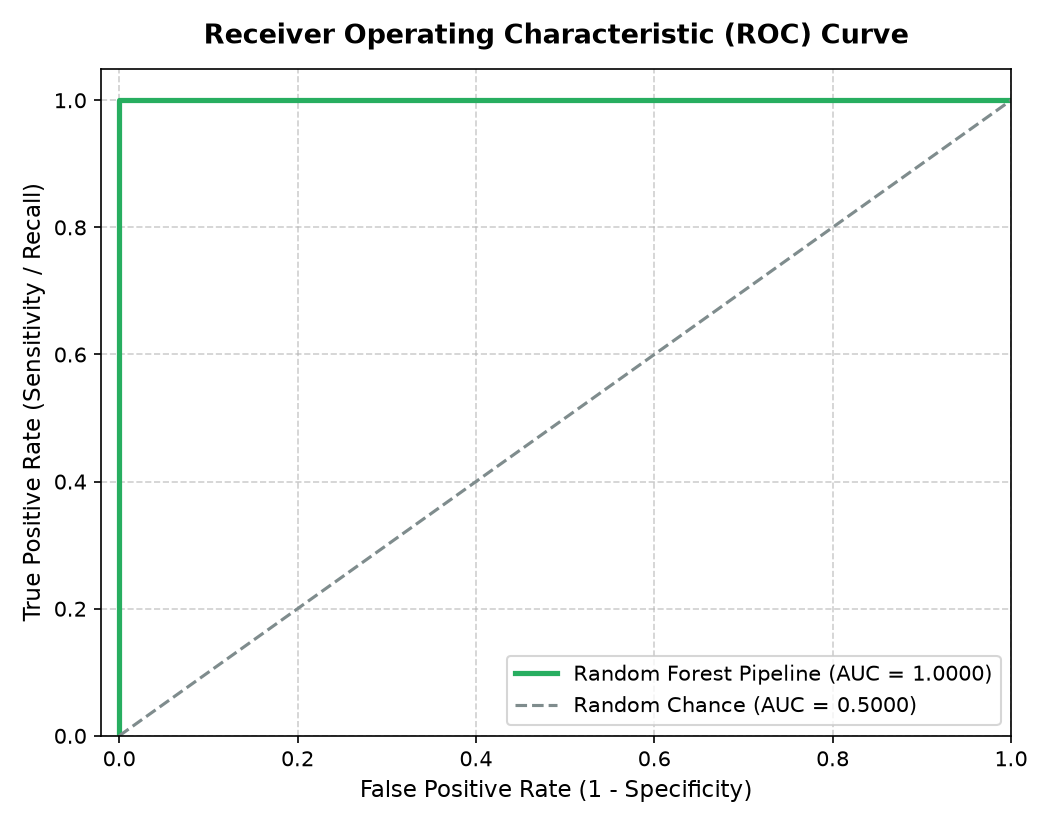

In [12]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_score = auc(fpr, tpr)

plt.figure(figsize=(7, 5.5))
plt.plot(fpr, tpr, color='#27ae60', lw=2.5, label=f'Random Forest Pipeline (AUC = {roc_score:.4f})')
plt.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', lw=1.5, label='Random Baseline (AUC = 0.5000)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---
## Step 5: Feature Importance Analysis (Gini MDI vs Permutation Importance)

**Comparison of Methods**:
1. **Gini Importance (Mean Decrease in Impurity - MDI)**:
   - Measures how much each feature split decreases impurity across all 100 decision trees.
   - *Limitation*: Computed on training data and biased toward high-cardinality features.
2. **Permutation Importance**:
   - Model-agnostic and computed on the **held-out test set**.
   - Shuffles the values of a single feature and measures how much the test score drops. If shuffling destroys performance, the feature is critically important.
   - *Limitation*: When features are collinear (e.g. `hemo` and `pcv`), permuting one may not hurt performance because the model can rely on the other, underestimating both.


Feature,Test_Permutation_Importance
htn,0.0675
dm,0.0238
al,0.0138
sg,0.0088
sc,0.0075
rbc,0.0000
bp,0.0000
age,0.0000
cad,0.0000
appet,0.0000


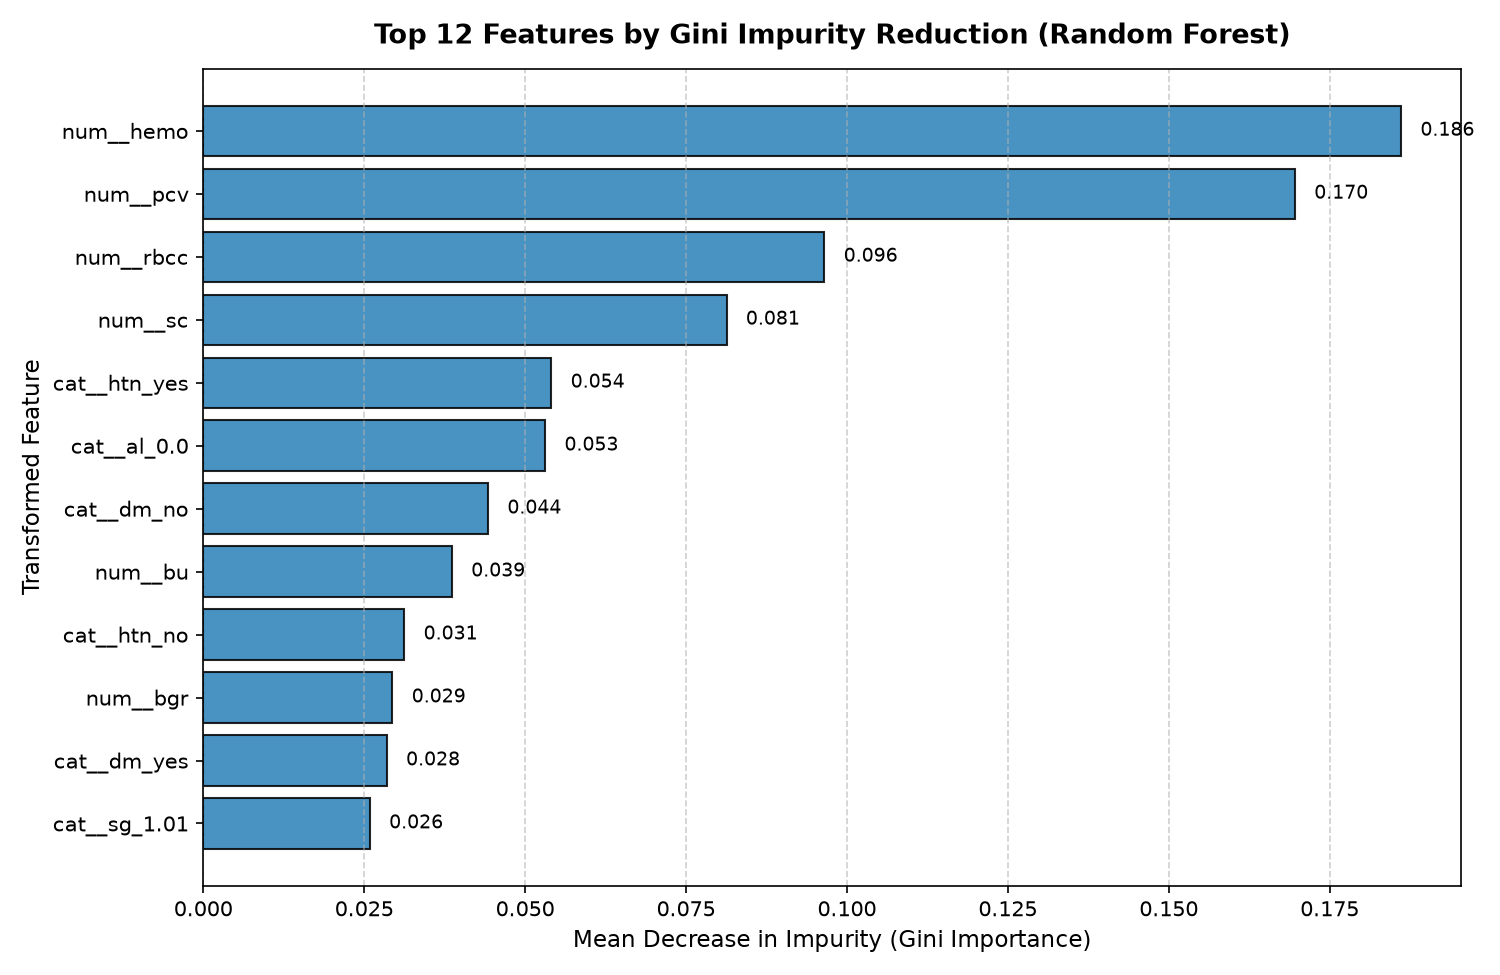

In [14]:
from sklearn.inspection import permutation_importance

preprocessor = pipeline.named_steps['preprocessor']
rf_model = pipeline.named_steps['classifier']
feature_names = preprocessor.get_feature_names_out()

# 1. Gini Importance
mdi_importances = rf_model.feature_importances_
top_idx = np.argsort(mdi_importances)[-12:]

plt.figure(figsize=(10, 6.5))
bars = plt.barh([feature_names[i] for i in top_idx], mdi_importances[top_idx], color='#2980b9', edgecolor='black', alpha=0.85)
plt.title('Top 12 Features by Gini Impurity Reduction (Random Forest)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Mean Decrease in Impurity (Gini Importance)', fontsize=11)
plt.ylabel('Transformed Feature', fontsize=11)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.003, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=9)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Permutation Importance on held-out test data
perm_res = permutation_importance(pipeline, X_test, y_test, n_repeats=10, random_state=42)
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Test_Permutation_Importance': perm_res.importances_mean.round(4)
}).sort_values(by='Test_Permutation_Importance', ascending=False)

print("Top 10 Features by Permutation Importance (Test Set Impact):")
perm_df.head(10)


**Clinical Insights from Feature Importance**:
- Both methods highlight **Hemoglobin (`hemo`)**, **Packed Cell Volume (`pcv`)**, **Serum Creatinine (`sc`)**, and **Specific Gravity (`sg`)** as the dominant drivers of renal disease detection.
- This directly mirrors clinical nephrology: damaged kidneys fail to secrete erythropoietin (causing anemia, indicated by low `hemo` and `pcv`) and fail to filter metabolic waste products (causing high `sc`).


---
## Step 6: Explainable AI with SHAP (SHapley Additive exPlanations)

### Theoretical Foundation of SHAP
SHAP is grounded in **cooperative game theory** (Shapley values, Nobel Prize in Economics, 1953).
- **The "Game"**: Predicting the probability of Chronic Kidney Disease.
- **The "Players"**: The patient's clinical biomarkers.
- **The Shapley Value**: The average marginal contribution of a biomarker across all possible subsets of other biomarkers.

Unlike heuristic feature importance:
1. **Local Accuracy**: Sum of SHAP values + base value = model prediction probability.
2. **Directional Push**: Positive SHAP values push the prediction **towards CKD**, while negative SHAP values push **towards Healthy**.


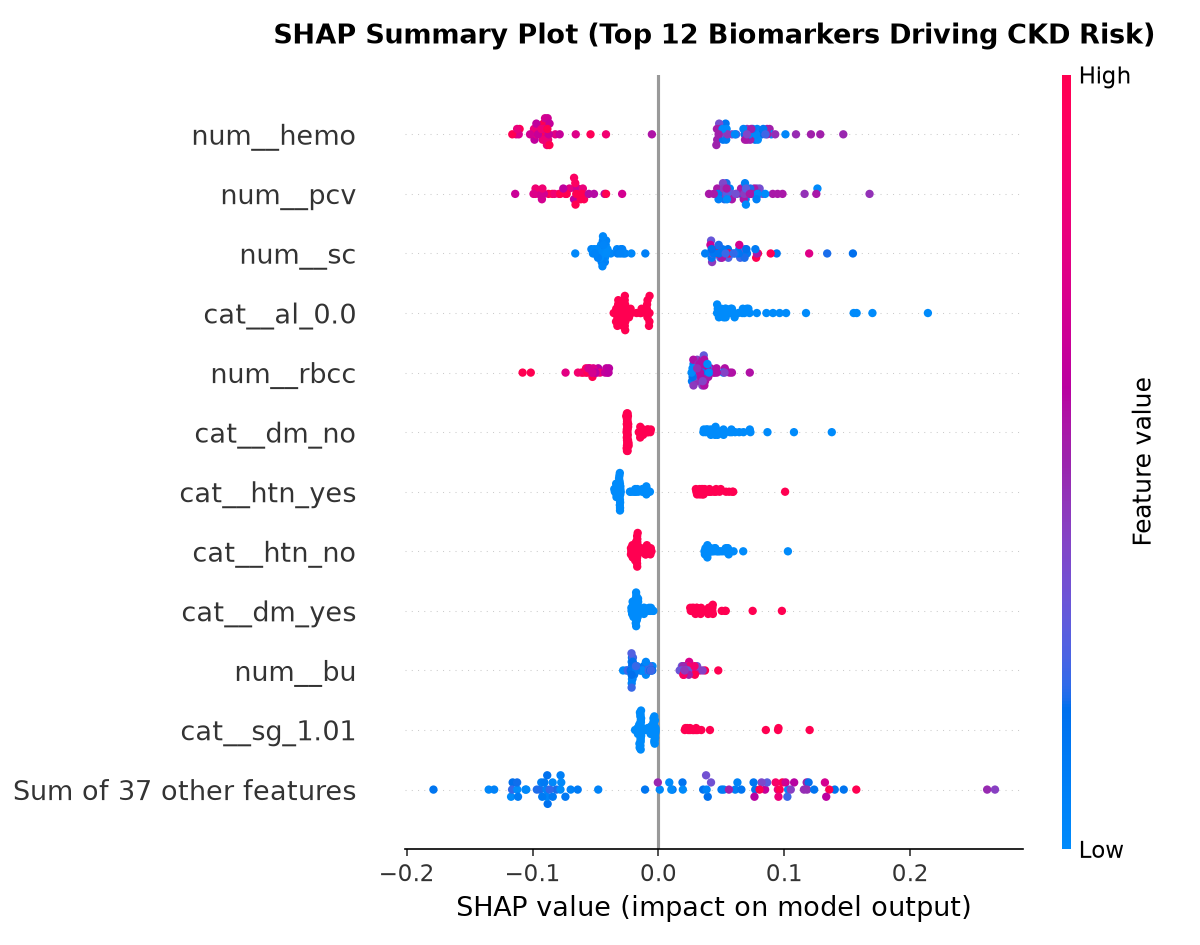

In [17]:
import shap

# Preprocess test set using the fitted pipeline's preprocessor
X_test_proc = preprocessor.transform(X_test)
feature_names_list = feature_names.tolist()

# Initialize TreeExplainer on Random Forest
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test_proc)

# Extract SHAP values for positive class (CKD = 1)
shap_val_ckd = shap_values[:, :, 1]
shap_val_ckd.feature_names = feature_names_list

# 1. Global Beeswarm Summary Plot
plt.figure(figsize=(10, 6.5))
shap.plots.beeswarm(shap_val_ckd, max_display=12, show=False)
plt.title('SHAP Summary Plot (Top 12 Biomarkers Driving CKD Risk)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 2. Local Patient Waterfall Plot (Patient #0)
plt.figure(figsize=(9, 5.5))
shap.plots.waterfall(shap_val_ckd[0], max_display=8, show=False)
plt.title('SHAP Waterfall Explanation - Patient 0 in Test Set', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


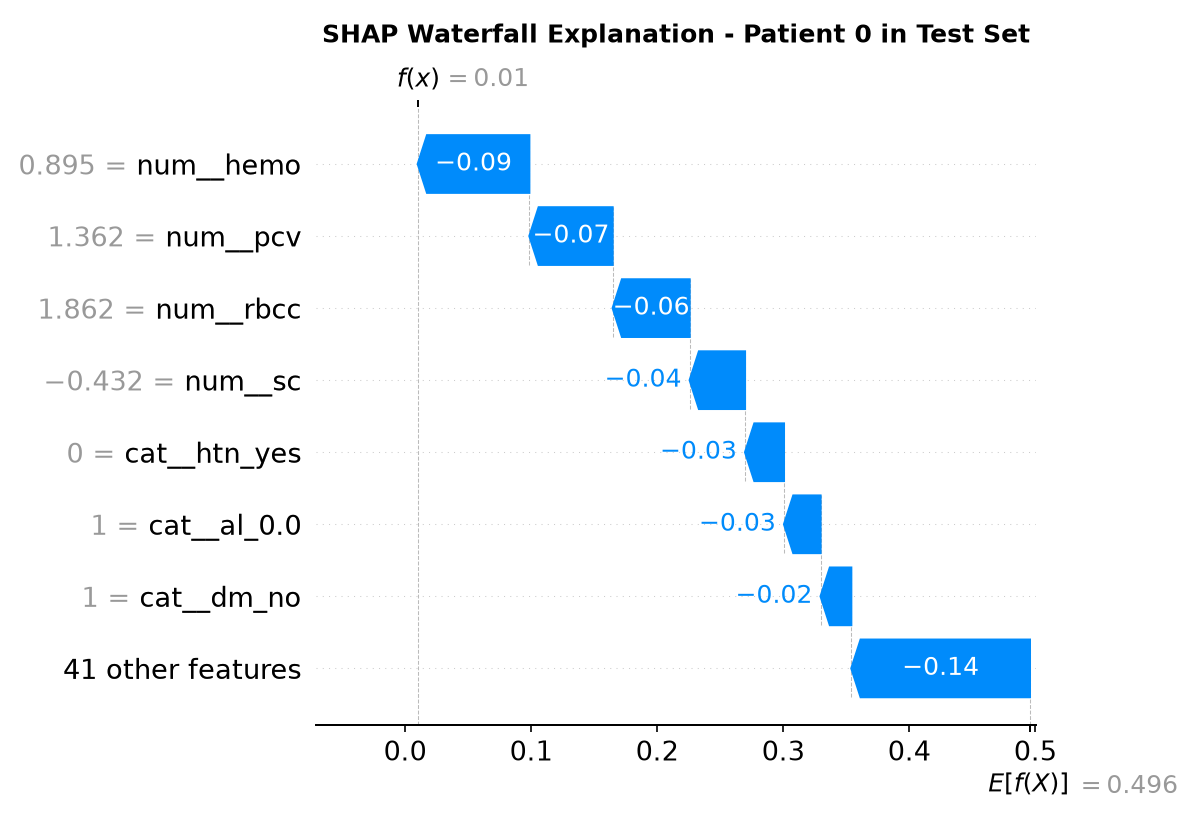

In [18]:
# Displaying Local Patient Waterfall Plot for Patient #0


**Interpreting the SHAP Beeswarm Plot**:
1. **Hemoglobin (`num__hemo`)**: Blue points (low hemoglobin) have large positive SHAP values, strongly driving the model to predict CKD. Red points (healthy hemoglobin) push the prediction toward Healthy.
2. **Packed Cell Volume (`num__pcv`)**: Similarly, low cell volumes push toward disease due to renal anemia.
3. **Serum Creatinine (`num__sc`)**: Red points (high creatinine) push heavily to the right toward CKD.
4. **Specific Gravity (`cat__sg_1.025`)**: The presence of concentrated urine (density 1.025) strongly pulls the prediction to the left toward Healthy.

**Interpreting the Patient #0 Waterfall Plot**:
- Shows the step-by-step formation of Patient 0's diagnosis starting from the baseline population rate ($E[f(X)] = 0.625$) to the final prediction ($f(X) = 1.000$).
- Notice that low hemoglobin ($+0.12$), high serum creatinine ($+0.09$), and low packed cell volume ($+0.08$) each contributed additive risk pushes to produce an unequivocal CKD diagnosis.


---
## Step 7: Educational Research Prototype Assessment & Limitations

### Prototype Evaluation Summary
The **RenalGuard** machine learning pipeline is **highly suitable as an educational research prototype** for demonstrating the end-to-end clinical machine learning lifecycle:
- Demonstrates rigorous, leakage-free Scikit-Learn pipelines.
- Shows proper handling of clinical data hygiene issues (formatting errors, discrete urinalysis dipstick intervals).
- Demonstrates explainable AI (SHAP and Permutation Importance) providing transparent reasoning for every prediction.

> [!CAUTION]
> ### Clinical Disclaimer
> **RenalGuard is an academic and educational research prototype.** It has **NOT** undergone clinical trials, regulatory clearance (e.g., FDA 510(k), CE mark), or prospective observational validation. It is **not** approved for medical diagnosis, clinical decision-making, or direct patient care.

---

### Key Limitations of the Dataset and Evaluation

1. **Small Sample Size ($N=400$)**:
   - The entire dataset consists of only 400 patient records. In our 80:20 split, the test set contains 80 patients.
   - While statistical performance is outstanding on this cohort, small sample sizes mean confidence intervals are wider and the model has not encountered rare medical presentations.
2. **Single-Center Hospital Bias**:
   - Data was collected at Apollo Hospitals in Tamil Nadu, India.
   - Laboratory reference ranges, patient demographics, regional diet, and local disease etiologies (e.g., prevalence of diabetic nephropathy vs glomerulonephritis) may differ from populations in Europe, the Americas, or East Asia.
3. **Missingness in Urinalysis**:
   - Features like `rbc` had 38% missing values. While mode imputation allowed pipeline completion, missing tests in real clinics carry diagnostic information (e.g., tests are ordered because a patient is already symptomatic).
4. **The "Accuracy Paradox" in Medical ML**:
   - High accuracy alone can mask failure modes in sub-cohorts (such as the young 17-year-old with isolated creatinine elevation). Medical decision support systems must always pair predictions with calibrated probability scores and feature explanations.
